# Space Science — From the Moon to the Outer Solar System

Once a vehicle leaves the atmosphere, navigation becomes orbital mechanics. Two
questions drive every mission: where are the planets, and which path between them
costs the least fuel?

This notebook builds up in stages. It starts with the simplest analytic model, a
two-impulse Hohmann transfer. It ends with a full N-body Extended Kalman Filter (EKF)
cruise that includes real-time trajectory correction. An N-body model includes the
gravity of several bodies at once, not just one.

| Section | Topic | Key API |
|---------|-------|---------|
| 1 | Trans-lunar coast — Earth ↔ Moon | `TransLunarModel`, `lunar_porkchop` |
| 2 | Earth → Mars: Hohmann → porkchop → N-body EKF | `hohmann_transfer`, `porkchop`, `InterplanetaryModel` |
| 2d | Mid-course TCM — trajectory correction | `InterplanetaryModel(control=True)` |
| 3 | Earth → Jupiter: same framework, longer cruise | `InterplanetaryModel`, `porkchop` |
| 4 | Gravity assist: Jupiter→Saturn slingshot | `gravity_assist`, `hohmann_sequence`, `flyby_porkchop` |
| 5 | Second TCM from EKF covariance at 80 % TOF | EKF covariance → re-Lambert |
| 6 | Cassini VVEJGA: Earth→V→V→E→J→Saturn replication | `chain_lambert`, `plot_multi_leg` |

**Transfer methods used in this notebook:**

| Method | What it solves | Accuracy | When used |
|--------|---------------|----------|-----------|
| **Hohmann** | Two-impulse transfer between *circular, coplanar* orbits — solved with a formula | Approximate | Quick Δv and time-of-flight (TOF) estimates |
| **Lambert** | The orbit between any two positions in a given time of flight, solved numerically | Exact (two-body) | Porkchop scan, trajectory seeds |
| **N-body EKF** | A Lambert initial state, propagated under Sun and planet gravity, and filtered | Realistic | Cruise simulation and navigation |

This notebook gets planet positions from the astropy `builtin` ephemeris. An ephemeris
is a table of body positions over time. This ephemeris uses JPL data and needs no
network access.


In [1]:
%pip install numpy matplotlib astropy > /dev/null
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05
from astropy.time import Time
np.seterr(all="ignore")

from kalman.apps.astro.space import (TransLunarModel, InterplanetaryModel,
                               TrajectoryControlManeuver,
                               hohmann_transfer, lambert, porkchop, best_departure,
                               plot_solar_system, plot_porkchop,
                               gravity_assist, hohmann_sequence, flyby_porkchop,
                               plot_flyby_porkchop, plot_gravity_assist, plot_two_leg,
                               chain_lambert, plot_multi_leg,
                               lunar_porkchop, plot_porkchop)
from kalman.runtime.astro import (planet_positions, body_state, launch_site_state,
                                  R_EARTH, KM, D_MOON, GM_EARTH, GM_SUN, LU, DAY, D_SUN)
AU = D_SUN                    # 1 astronomical unit in Mm


Note: you may need to restart the kernel to use updated packages.


AttributeError: module 'numpy' has no attribute 'in1d'

## Step 0 — The Solar System Right Now

`planet_positions()` returns the heliocentric position of each planet and the Moon at
a chosen time. Heliocentric means measured from the Sun. The function reads this
position from the JPL-style `builtin` ephemeris. No download is required.


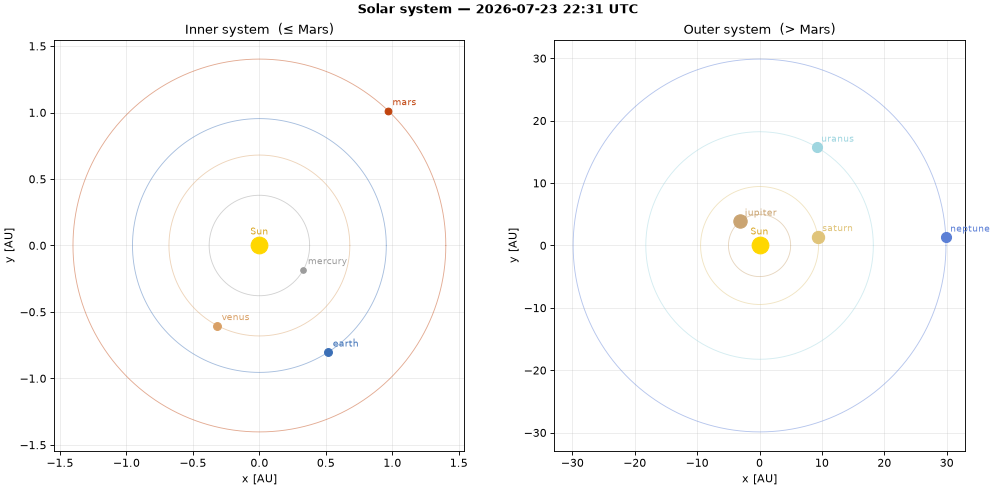

In [ ]:
# Where is everything right now? Sun + planet orbits + live positions, to scale.
plot_solar_system(Time.now())
plt.show()

## Step 1 — Trans-Lunar Coast

A spacecraft coasts under the gravity of Earth, the Moon, and the Sun. It flies a
free-return trajectory. The spacecraft starts on a trans-lunar ellipse. It swings
around the Moon and returns to Earth. This is the Apollo flight path.

Ground stations track only the spacecraft's position, not its velocity. The EKF
reconstructs full position and velocity from these three position values at each
step.

The analytic model here uses a circular Moon orbit. Step 1c below sets
`use_ephemeris=True`. This loads the exact JPL Moon position and adds a launch-window
scan with `lunar_porkchop`.


In [ ]:
moon = TransLunarModel(moon_phase_deg=133.0, sun_phase_deg=60.0, dt_s=180.0, track_km=5.0, n_sub=4)
r0 = R_EARTH + 400 * KM                            # 400 km parking orbit
a_tx = 0.5 * (r0 + D_MOON)
v_tli = np.sqrt(GM_EARTH * (2.0 / r0 - 1.0 / a_tx)) + 0.034     # trans-lunar injection burn
x0 = np.array([[r0], [0], [0], [0], [v_tli], [0]])
P0 = np.diag([(50 * KM) ** 2] * 3 + [0.01 ** 2] * 3)

moon.initial_state(x0, P0=P0)
flight = moon.sample(7.5 * DAY, process_noise=False)   # 7.5 days — full free-return
est = moon.filter(flight.zk)

# Splashdown index: first re-entry (radius < R_EARTH) after the lunar flyby.
radius_km = np.linalg.norm(np.asarray(flight.xk)[:, :3], axis=1)
outbound_steps = int(4 * DAY / moon._dt)
apoapsis_idx = int(radius_km[:outbound_steps].argmax())         # apoapsis ≈ Moon flyby
splashdown_k = int(apoapsis_idx + np.argmax(radius_km[apoapsis_idx:] < R_EARTH))
print(f"Splashdown at t = {splashdown_k * moon._dt / DAY:.2f} d  (step {splashdown_k})")

# Earth-only twin (no Moon): the Keplerian counterfactual, showing where the craft
# drifts without the lunar slingshot. Sampled to half its period; the animation
# auto-extends to periapsis return.
kepler_twin = TransLunarModel(moon_phase_deg=133.0, sun_phase_deg=60.0, dt_s=180.0,
                              bodies=("earth",), n_sub=4)
kepler_twin.initial_state(x0, P0=P0)
kepler = kepler_twin.sample(10.5 * DAY, process_noise=False)

moon.plot(est, sample=flight, interactive=True, frames=30, kepler=kepler, nmax=splashdown_k)


Splashdown at t = 6.65 d  (step 3191)


### Step 1c — Real Moon Geometry and the Trans-Lunar Launch Window

`use_ephemeris=True` sets the Moon and Sun phases from the real ephemeris at a chosen
`epoch`. This replaces the illustrative analytic angles used in Step 1.

`lunar_porkchop` scans departure dates. For each date, it solves a geocentric Lambert
arc to the Moon's exact position. This search finds the monthly trans-lunar injection
(TLI) launch windows. TLI is the burn that sends the spacecraft toward the Moon. This
scan is the lunar version of the interplanetary porkchop scan in Step 2b.


In [ ]:
moon_eph = TransLunarModel(dt_s=180.0, track_km=5.0, n_sub=4,
                           use_ephemeris=True, epoch="2026-11-06")
moon_eph.initial_state(x0, P0=P0)                      # same parking-orbit injection as Step 1
flight_eph = moon_eph.sample(5.5 * DAY, process_noise=False)
est_eph = moon_eph.filter(flight_eph.zk)
moon_eph.plot(est_eph, sample=flight_eph, interactive=True)
plt.show()


best TLI window: 2026-12-27 | tof 5.0 d | Δv_TLI 3.08 km/s  Δv_LOI 0.82 km/s


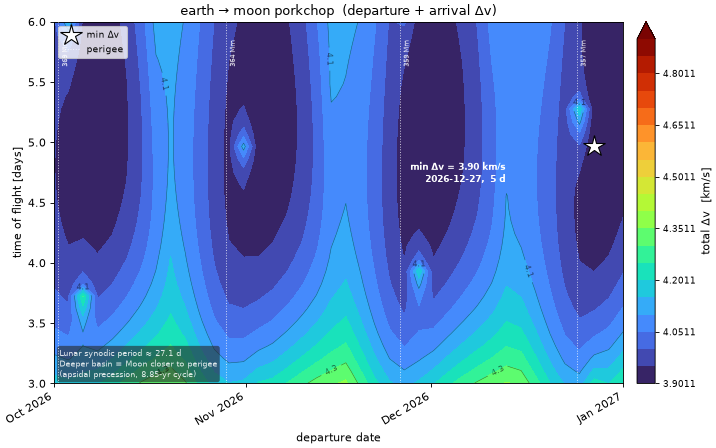

In [ ]:
from kalman.apps.astro.space import lunar_porkchop
lunar_grid = lunar_porkchop(start="2026-10-01", end="2027-01-01", n_dep=40, tof_days=(3, 6), n_tof=30)
lbest = lunar_grid["best"]
print("best TLI window:", lbest["dep_date"].iso[:10],
      "| tof %.1f d | \u0394v_TLI %.2f km/s  \u0394v_LOI %.2f km/s"
      % (lbest["tof_days"], lbest["dv_depart_kms"], lbest["dv_arrive_kms"]))
plot_porkchop(lunar_grid)
plt.show()

#### Why Do Successive Basins Get Deeper?

Each **basin** in the plot is one monthly TLI window. The Moon completes one orbit
every 29.5 synodic days; the white dotted lines mark these windows.

The basins get deeper because of the Moon's orbit. This orbit precesses (rotates)
over an 8.85-year cycle, called apsidal precession. The orbit's eccentricity is about
0.055. In late 2026, the Moon's perigee (closest point to Earth) is approaching its
minimum distance. So each later window finds a closer Moon:

| Perigee | Distance | TLI Δv |
|---------|----------|--------|
| Oct 02  | 369 300 km | shallowest |
| Oct 29  | 364 400 km | ↓ |
| Nov 26  | 359 400 km | ↓ |
| **Dec 24** | **356 700 km** | **deepest** |

A closer Moon needs a shorter transfer-orbit semi-major axis. A shorter axis needs
less TLI energy. So the deepest basin lines up with the closest perigee.

The optimal date is **Dec 27**, three days after perigee, not on perigee itself. At
exact perigee the Moon moves fastest. This raises the cost of the lunar-orbit
insertion (LOI) burn at arrival. The combined TLI and LOI minimum falls three days
later.

The time of flight (TOF) at the minimum also shifts: about 3.5 days in October, about
5 days in November. Two lunar cycles cause this shift. The synodic month (29.5 days)
sets the window spacing. The anomalistic month (27.5 days, perigee to perigee) is
shorter. Because the two cycles differ, each window catches the Moon at a later point
in its orbit.


## Step 2 — Earth to Mars: A First Estimate With the Hohmann Transfer

The Hohmann transfer is the two-impulse path between two circular, coplanar orbits
that uses the least fuel. It gives three numbers directly: the departure Δv, the
arrival Δv, and the time of flight (TOF).

Every real mission targets these three numbers, even though real orbits are elliptic
and inclined. In practice, engineers always refine the estimate with a numerical
Lambert solve (Step 2b).

For Earth to Mars, the Hohmann transfer gives about 5.6 km/s total Δv and a flight of
about 260 days. Earth and Mars must also be in the right relative position for
launch. If a mission misses this window, the wait for the next one is the synodic
period, about 780 days.


In [ ]:
hohmann = hohmann_transfer("earth", "mars")
for key, value in hohmann.items():
    is_time = hasattr(value, "iso")
    formatted = value.iso[:16] if is_time else round(value, 3) if isinstance(value, float) else value
    print(f"{key:24s}: {formatted}")

departure               : earth
target                  : mars
r1_AU                   : 1.016
r2_AU                   : 1.469
dv_depart_kms           : 2.584
dv_arrive_kms           : 2.355
dv_total_kms            : 4.94
tof_days                : 252.986
phase_angle_deg         : 40.026
synodic_period_days     : 879.383
next_departure          : 2026-12-25 19:14


## Step 2b — Launch Window: The Porkchop Scan (Lambert)

Real orbits are elliptic and inclined, so the Hohmann transfer is only an
approximation. Lambert's problem solves for the orbit between two arbitrary
positions, in a given time of flight. It needs no circular or coplanar orbits.

The notebook solves Lambert's problem at every (departure date, TOF) point on a grid.
This produces the porkchop plot: contours of total Δv across the launch window.

The grid point with the lowest Δv seeds the cruise. `best_departure` extracts this
point and builds the initial state vector `x0 = [r_Earth, v_Lambert]` for the EKF.

> **Lambert vs. Hohmann:** Lambert is exact for two-body dynamics, with the Sun as
> the only gravity source. The N-body EKF below adds the gravity of the other
> planets on top.


best departure:

 2026-10-28 | tof 311 d | Δv_depart 3.05 km/s  C3 9.3 km²/s²


/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 86 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 86 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


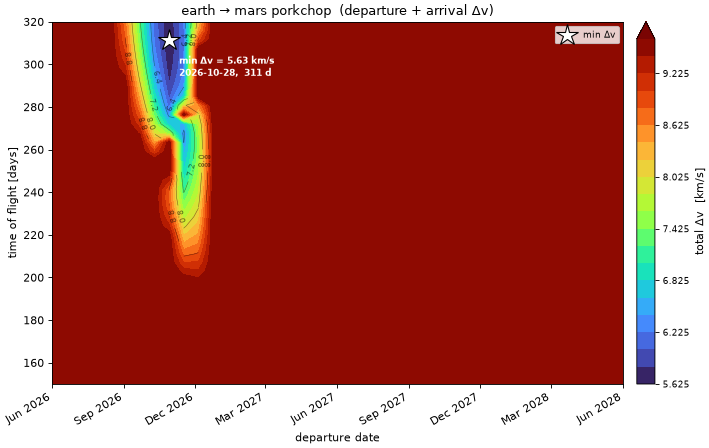

launch from Kennedy Space Center at 05:46 UTC  (Earth-rotation assist 0.364 km/s)


In [ ]:
grid = porkchop("earth", "mars", start="2026-06-01", end="2028-06-01",
                n_dep=40, tof_days=(150, 320), n_tof=40)
best = grid["best"]
print("best departure:", best["dep_date"].iso[:10],
      "| tof %.0f d" % best["tof_days"],
      "| \u0394v_depart %.2f km/s  C3 %.1f km\u00b2/s\u00b2" % (best["dv_depart_kms"], best["c3_km2s2"]))

plot_porkchop(grid)
plt.show()

# Earth rotation: best time of day from a launch site (needs network for geocoding/IERS).
try:
    site_best = best_departure("earth", "mars", start="2026-06-01", end="2028-06-01",
                               n_dep=40, tof_days=(150, 320), n_tof=40, site="Kennedy Space Center")
    print("launch from %s at %s UTC  (Earth-rotation assist %.3f km/s)"
          % (site_best["site"], site_best["launch_time"].iso[11:16], site_best["rotation_assist_kms"]))
except Exception as exc:
    print("launch-site geocoding skipped (offline):", type(exc).__name__)

## Step 2c — N-Body EKF Cruise: Earth to Mars

The notebook propagates the Lambert initial state under the gravity of the Sun,
Venus, Jupiter, and Saturn. This is N-body dynamics: gravity from several bodies at
once.

The model observes only position. Deep-space tracking measures range and range rate;
this notebook models that as three Cartesian position fixes from the Deep Space
Network (DSN). The EKF reconstructs velocity from these position measurements.

The Lambert solution is a two-body solution: it ignores the other planets. So the
extra planetary gravity slowly pulls the spacecraft off course, and this error grows
over the cruise. Step 2d shows how a mid-course burn, called a trajectory correction
manoeuvre (TCM), removes this error before arrival.


In [ ]:
tof = best["tof_days"]
cruise = InterplanetaryModel("earth", "mars", epoch=best["dep_date"], span_days=tof + 20,
                             dt_s=43200.0, track_Mm=0.02)
cruise.initial_state(best["x0"].reshape(-1, 1), P0=np.diag([1., 1., 1., 1e-4, 1e-4, 1e-4]))
trip = cruise.sample(tof * DAY, process_noise=False)
est = cruise.filter(trip.zk)
truth_state = np.asarray(trip.xk)
est_state = np.asarray(est.xk)
err = np.linalg.norm(truth_state[:, :3] - est_state[:, :3], axis=1)
print("EKF mean position error: %.1f km  (final %.1f km)" % (err.mean() * 1e3, err[-1] * 1e3))
print("perturbing bodies:", cruise._field.bodies)
cruise.plot(est, sample=trip, interactive=True, frames=30)     # interactive cruise replay

EKF mean position error: 15.6 km  (final 6.9 km)
perturbing bodies: ('mercury', 'venus', 'jupiter', 'saturn')


## Step 2d — Mid-Course Trajectory Correction Manoeuvres (TCMs)

Real interplanetary missions use a standard TCM schedule:

| TCM | Epoch | Purpose |
|-----|-------|---------|
| TCM-1 | day 5 | The main correction. It fixes the launch-injection error with maximum leverage. |
| TCM-2 | day 30 | A mid-course trim of the remaining N-body drift. |
| TCM-3 | day 90 | An optional fine adjustment, often under 1 m/s. |

**Why early burns work best: the leverage principle.** A burn early in the flight has
more time to change the arrival point than a burn late in the flight. For example, a
Δv of 1 m/s applied 175 days before Mars shifts the arrival point by:

$$\Delta r_{\rm arr} \approx \Delta v \times t_{\rm rem} = 1\,\text{m/s} \times 175\,\text{d} \times 86400\,\text{s/d} \approx 15\,100\,\text{km}$$

The same 1 m/s burn, fired only 5 days before arrival, moves the arrival point by
only 430 km. This is why TCM-1 carries most of the mission's correction budget.

**`TrajectoryControlManeuver`** is a `KalmanController` subclass. It automates the TCM
process in four steps:

1. At each scheduled epoch, it re-solves Lambert's problem. It uses the current EKF
   position and the Mars arrival position, and finds the required velocity.
2. It computes `Δv = v_needed − v_current`, and caps this value at `max_dv_kms` (50
   m/s).
3. It applies the Tsiolkovsky rocket equation. This gives the propellant consumed and
   the burn duration. The burn lasts seconds to minutes; it is not an instant push.
4. It returns the velocity change. The EKF applies this change as a control input
   during its prediction step.

This notebook uses spacecraft parameters from the MRO and InSight missions: 600 kg
dry mass, 1200 kg wet mass, specific impulse (Isp) 220 s, thrust 22 N. These values
match small hydrazine thrusters used for correction burns, not a main engine.


In [ ]:
from astropy.time import TimeDelta
from kalman.framework.io.record import KalmanRecord

mc = InterplanetaryModel("earth", "mars", epoch=best["dep_date"], span_days=tof + 20,
                         dt_s=43200.0, control=True, track_Mm=0.02)
dt = mc._dt
N = int(round(tof * DAY / dt))
arrival  = best["dep_date"] + TimeDelta(N * dt * 1000.0, format="sec")
mars_arr = body_state("mars", arrival)[0]

# ── Realistic injection error: ±2 m/s per axis (~3.5 m/s total 3-D) ──────
# Real TCMs correct launch-injection errors of 5–30 m/s (MRO TCM-1 = 18.5 m/s).
# ±2 m/s per axis is conservative/optimistic; the leverage physics still shows clearly.
rng = np.random.default_rng(7)
inj = np.r_[np.zeros(3), rng.normal(0, 0.002, 3)]   # km/s (~2 m/s each axis)
x0  = best["x0"] + inj
print("Injection error: %.1f m/s  (3-D)" % (np.linalg.norm(inj[3:]) * 1e3))
print("Heliocentric departure speed: %.2f km/s  "
      "(Earth ~29.8 km/s → +%.2f km/s from TLI)"
      % (np.linalg.norm(x0[3:]), np.linalg.norm(x0[3:]) - 29.8))
print("Spacecraft: %.0f kg dry / %.0f kg wet   Isp 220 s   thrust 22 N"
      % (mc.SPACECRAFT_DRY_MASS_KG, mc.SPACECRAFT_WET_MASS_KG))
print()

# ── TrajectoryControlManeuver — Lambert targeting + Tsiolkovsky burns ──────
# Pass the spacecraft parameters from the model constants (can override per mission).
tcm = TrajectoryControlManeuver(
    mc, mars_arr, N * dt,
    tcm_days=[5.0, 30.0, 90.0],              # canonical schedule: early burns dominate
    dry_mass_kg=mc.SPACECRAFT_DRY_MASS_KG,
    wet_mass_kg=mc.SPACECRAFT_WET_MASS_KG,
    Isp_s=220.0, thrust_N=22.0,
    max_dv_kms=0.050,                         # 50 m/s cap — real TCMs rarely exceed this
)

# ── Propagate truth WITH TCM burns (planning / autopilot pass) ────────────
def autopilot(x0, tcm_ctrl):
    """N-body truth propagation with TCM burns applied at scheduled epochs."""
    x = np.asarray(x0, float).ravel().copy()
    hist = [x.copy()]
    P_nav = np.eye(6)
    for i in range(N):
        u = tcm_ctrl._policy(x.reshape(-1, 1), P_nav, i * dt)
        x = mc.f(x, u=(u if np.any(u != 0) else None), t=i * dt).ravel()
        hist.append(x.copy())
    return np.array(hist)

hist_cor = autopilot(x0, tcm)

# No-TCM open-loop truth (for counterfactual plot)
mc_nb = InterplanetaryModel("earth", "mars", epoch=best["dep_date"], span_days=tof + 20,
                             dt_s=43200.0, track_Mm=0.02)
mc_nb.initial_state(x0.reshape(-1, 1))
trip_nom = mc_nb.sample(N * dt, process_noise=False)
hist_nom = np.asarray(trip_nom.xk)

miss_nom = np.linalg.norm(hist_nom[-1, :3]  - mars_arr) * 1e3   # km
miss_cor = np.linalg.norm(hist_cor[-1, :3]  - mars_arr) * 1e3
print("Arrival miss WITHOUT TCMs: %8.0f km  (%.3f AU)" % (miss_nom, miss_nom / (AU * 1e3)))
print("Arrival miss WITH TCMs   : %8.0f km" % miss_cor)
print()
tcm.summary()

Injection error: 0.8 m/s  (3-D)
Heliocentric departure speed: 32.97 km/s  (Earth ~29.8 km/s → +3.17 km/s from TLI)
Spacecraft: 600 kg dry / 1200 kg wet   Isp 220 s   thrust 22 N



Arrival miss WITHOUT TCMs:  1047417 km  (0.007 AU)
Arrival miss WITH TCMs   :    22114 km

TCM Summary
────────────────────────────────────────────────────────────────────────────
  TCM-1   t=   5.0 d  Δv=    4.42 m/s  burn= 240.9 s  Δm=  2.46 kg  m_after=1197.54 kg  TOF_rem=  306 d
  TCM-2   t=  30.0 d  Δv=    0.43 m/s  burn=  23.3 s  Δm=  0.24 kg  m_after=1197.31 kg  TOF_rem=  282 d
  TCM-3   t=  90.0 d  Δv=    0.42 m/s  burn=  23.1 s  Δm=  0.24 kg  m_after=1197.07 kg  TOF_rem=  222 d
────────────────────────────────────────────────────────────────────────────
  TOTAL   Δv=    5.27 m/s   Δm=  2.93 kg   propellant left: 597.07 kg


### Visualising the Corrections

The EKF runs closed-loop. It receives noisy DSN position fixes from the true
trajectory, which includes the TCM burns. At each scheduled epoch, the
`TrajectoryControlManeuver` controller re-solves Lambert's problem and computes Δv
from the EKF's estimate, not from the true state. Because the EKF estimate is not
exactly the true state (navigation noise), the filter's burns may differ slightly
from the true-pass burns.

Two plots follow:
- A static overview: departure, each TCM event (marked ×), and Mars arrival.
- An interactive replay: orange Δv arrows mark the exact burn frame. A grey dashed
  line shows the uncorrected path. A gravity readout updates at each step.


EKF mean position error: 54403.9 km  (final 90179.9 km)

TCM Summary
────────────────────────────────────────────────────────────────────────────
  TCM-1   t=   5.0 d  Δv=   30.69 m/s  burn=1662.2 s  Δm= 16.95 kg  m_after=1183.05 kg  TOF_rem=  306 d
  TCM-2   t=  30.0 d  Δv=   32.21 m/s  burn=1719.4 s  Δm= 17.53 kg  m_after=1165.52 kg  TOF_rem=  282 d
  TCM-3   t=  90.0 d  Δv=   44.85 m/s  burn=2351.4 s  Δm= 23.98 kg  m_after=1141.54 kg  TOF_rem=  222 d
────────────────────────────────────────────────────────────────────────────
  TOTAL   Δv=  107.75 m/s   Δm= 58.46 kg   propellant left: 541.54 kg


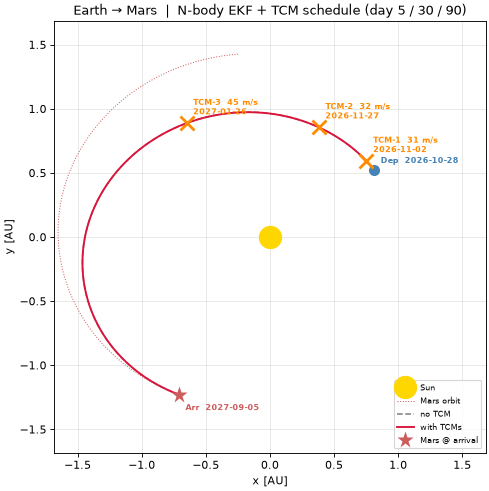

In [ ]:
from astropy.time import TimeDelta as _TD

# ── Run closed-loop EKF with TCM controller ───────────────────────────────
# Reset restores full tanks + clears the fired set so the controller
# re-computes burns from the EKF estimate (rather than the truth-pass state).
tcm.reset()
trip_mc = KalmanRecord(xk=hist_cor, zk=hist_cor[:, :3])
mc.initial_state(x0.reshape(-1, 1), P0=np.diag([1., 1., 1., 1e-4, 1e-4, 1e-4]))
est_mc = mc.filter(trip_mc.zk, uk=tcm)

err_mc = np.linalg.norm(
    np.asarray(est_mc.xk)[:, :3] - np.asarray(trip_mc.xk)[:, :3], axis=1)
print("EKF mean position error: %.1f km  (final %.1f km)" % (err_mc.mean() * 1e3, err_mc[-1] * 1e3))
print()
tcm.summary()   # burns computed from EKF estimate

# ── Static heliocentric overview ──────────────────────────────────────────
t_dep_str = best["dep_date"].iso[:10]
t_arr_str = arrival.iso[:10]

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0], [0], "o", color="gold", ms=20, label="Sun")
mars_trk = mc.planet_track("mars", N + 1) / AU
ax.plot(mars_trk[:, 0], mars_trk[:, 1], ":", color="indianred", lw=0.9, label="Mars orbit")
ax.plot(hist_nom[:, 0] / AU, hist_nom[:, 1] / AU, "--", color="0.5", lw=1.4, label="no TCM")
ax.plot(hist_cor[:, 0] / AU, hist_cor[:, 1] / AU, color="crimson", lw=1.7, label="with TCMs")
dep_pos = hist_cor[0, :2] / AU
ax.plot([dep_pos[0]], [dep_pos[1]], "o", color="steelblue", ms=10, mec="none", zorder=5)
ax.annotate(f"Dep  {t_dep_str}", dep_pos, xytext=(6, 6), textcoords="offset points",
            fontsize=7, color="steelblue", fontweight="bold")
for burn in tcm.burns:
    burn_idx = int(round(burn["t_ks"] / dt))
    burn_pos = hist_cor[burn_idx, :2] / AU
    burn_date_str = (best["dep_date"] + _TD(float(burn["t_ks"]) * 1e3, format="sec")).iso[:10]
    ax.plot([burn_pos[0]], [burn_pos[1]], "x", color="darkorange", ms=13, mew=2.5, zorder=6)
    ax.annotate("TCM-%d  %.0f m/s\n%s" % (burn["tcm_idx"], burn["dv_ms"], burn_date_str),
                burn_pos, xytext=(6, 8), textcoords="offset points",
                fontsize=7, color="darkorange", fontweight="bold")
mars_pos = mars_arr[:2] / AU
ax.plot([mars_pos[0]], [mars_pos[1]], "*", color="indianred", ms=16, mec="none", zorder=5,
        label="Mars @ arrival")
ax.annotate(f"Arr  {t_arr_str}", mars_pos, xytext=(6, -14), textcoords="offset points",
            fontsize=7, color="indianred", fontweight="bold")
lim = 1.15 * np.abs(hist_cor[:, :2] / AU).max()
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_aspect("equal", adjustable="box")
ax.autoscale(False)
ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.grid(alpha=0.3)
ax.legend(loc="lower right", fontsize=7.5)
ax.set_title("Earth → Mars  |  N-body EKF + TCM schedule (day 5 / 30 / 90)")
plt.show()

# ── Interactive EKF replay ────────────────────────────────────────────────
burns_for_plot = [(int(round(burn["t_ks"] / dt)), burn["dv_vec_kms"]) for burn in tcm.burns]
mc.plot(est_mc, sample=trip_mc, interactive=True, frames=30,
        burns=burns_for_plot, no_burn=trip_nom)

## Step 3 — Earth to Jupiter: Scaling to the Outer Solar System

Jupiter orbits at 5.2 astronomical units (AU) from the Sun; Mars orbits at 1.5 AU. So
the cruise to Jupiter lasts 2 to 3 years. At this distance, Saturn's gravity becomes a
measurable third-body effect, alongside the inner planets.

Apart from the distance, the method is the same as for Mars: a Hohmann estimate, then
a Lambert porkchop scan, then an N-body EKF cruise.

One difference stands out: Jupiter's synodic period is 398 days, just over a year.
So launch windows repeat almost every year. Mars launch windows repeat only every 26
months.


Earth -> Jupiter Hohmann:  Δv_total 14.32 km/s   TOF 1021 days   synodic period 408 days
best E->J departure: 2028-12-12 | tof 1010 d | Δv_total 14.73 km/s


/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 16 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 16 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/Softw

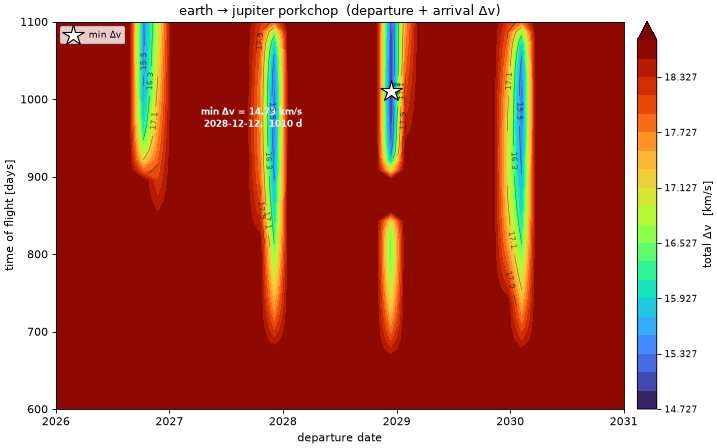

In [ ]:
h_jup = hohmann_transfer("earth", "jupiter")
print("Earth -> Jupiter Hohmann:  \u0394v_total %.2f km/s   TOF %.0f days   synodic period %.0f days"
      % (h_jup["dv_total_kms"], h_jup["tof_days"], h_jup["synodic_period_days"]))

grid_jup = porkchop("earth", "jupiter", start="2026-01-01", end="2031-01-01",
                    n_dep=40, tof_days=(600, 1100), n_tof=40)
best_jup = grid_jup["best"]
print("best E->J departure:", best_jup["dep_date"].iso[:10],
      "| tof %.0f d | \u0394v_total %.2f km/s" % (best_jup["tof_days"], best_jup["dv_total_kms"]))
plot_porkchop(grid_jup)
plt.show()


/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 527 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 527 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


EKF mean position error: 9181 km  (final 2200 km)
perturbing bodies: ('mercury', 'venus', 'mars', 'saturn')


/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 991 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 991 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


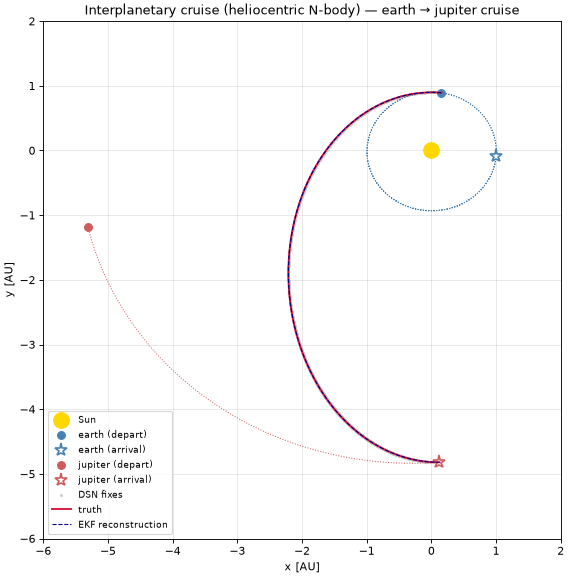

/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


In [ ]:
cruise_jup = InterplanetaryModel('earth', 'jupiter', epoch=best_jup['dep_date'],
                                 span_days=best_jup['tof_days'] + 60,
                                 perturbers=('mercury', 'venus', 'mars', 'saturn'),
                                 dt_s=86400.0, track_Mm=0.5)
cruise_jup.initial_state(best_jup['x0'].reshape(-1, 1),
                         P0=np.diag([1., 1., 1., 1e-4, 1e-4, 1e-4]))
trip_jup = cruise_jup.sample(best_jup['tof_days'] * DAY, process_noise=False)
est_jup  = cruise_jup.filter(trip_jup.zk)
err_jup  = np.linalg.norm(
    np.asarray(trip_jup.xk)[:, :3] - np.asarray(est_jup.xk)[:, :3], axis=1)
print('EKF mean position error: %.0f km  (final %.0f km)' % (err_jup.mean()*1e3, err_jup[-1]*1e3))
print('perturbing bodies:', cruise_jup._field.bodies)

# Static overview
cruise_jup.plot(est_jup, sample=trip_jup, xlim=(-6, 2), ylim=(-6, 2))
plt.show()

# Interactive EKF replay (below)
cruise_jup.plot(est_jup, sample=trip_jup, interactive=True, frames=30)


## Step 4 — Gravity Assist: Jupiter as a Stepping Stone to Saturn

A direct Hohmann transfer from Earth to Saturn costs 15.6 km/s and takes 6 years.
Chaining two legs through a free Jupiter flyby lowers the total to about 10 km/s. In
a flyby, Jupiter's gravity turns and speeds up the spacecraft at no fuel cost.
Voyager 1, Voyager 2, and Cassini all used this method.

### Step 4a — Analytic Estimate: The Hohmann Chain

`hohmann_sequence(["earth", "jupiter", "saturn"])` links two analytic Hohmann arcs.
Each leg is treated as circular and coplanar. The flyby uses the patched-conic
method: a hyperbolic approach at Jupiter, followed by a new heliocentric Hohmann
departure. This gives a quick lower bound on Δv. Finding the real optimum needs a
Lambert scan (Step 4c).


In [ ]:
from kalman.apps.astro.space import gravity_assist, hohmann_sequence, flyby_porkchop, plot_flyby_porkchop

# --- Analytic Hohmann chain: departure burn + free Jupiter flyby + Saturn arrival ---
hohmann_chain = hohmann_sequence(["earth", "jupiter", "saturn"])
print(f"Direct Earth→Saturn Hohmann :  Δv = {hohmann_chain['dv_direct_kms']:.2f} km/s")
print(f"Earth→Jupiter→Saturn (free flyby): Δv = {hohmann_chain['dv_total_kms']:.2f} km/s  "
      f"tof = {hohmann_chain['tof_days']:.0f} d")
for leg in hohmann_chain["legs"]:
    print(f"  {leg['departure']:8s} → {leg['target']:8s}: "
          f"Δv_dep={leg['dv_depart_kms']:.2f} km/s  "
          f"Δv_arr={leg['dv_arrive_kms']:.2f} km/s  "
          f"tof={leg['tof_days']:.0f} d")

Direct Earth→Saturn Hohmann :  Δv = 15.58 km/s
Earth→Jupiter→Saturn (free flyby): Δv = 10.21 km/s  tof = 4675 d
  earth    → jupiter : Δv_dep=8.72 km/s  Δv_arr=5.60 km/s  tof=1021 d
  jupiter  → saturn  : Δv_dep=1.72 km/s  Δv_arr=1.48 km/s  tof=3654 d


/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


### Step 4b — The Slingshot Geometry at Jupiter

Consider the flyby from Jupiter's own rest frame. The spacecraft arrives on a
hyperbolic path, curves around Jupiter, and leaves at the same speed. But in the
heliocentric frame (measured from the Sun), the spacecraft gains part of Jupiter's
orbital velocity, along its new direction.

Three parameters describe the flyby:

- **v_∞** (hyperbolic excess speed): the spacecraft's speed relative to Jupiter, far
  from Jupiter.
- **periapsis altitude, h** (closest-approach height): a closer flyby gives a larger
  turn angle, δ = 2 arcsin(μ_J / (μ_J + r_p v_∞²)).
- **heliocentric Δv**: the speed gain in the Sun-centred frame; a Jupiter flyby can
  add several km/s.

The next code cell calls `gravity_assist()`. It uses the Lambert-derived arrival v_∞
and a 500 km periapsis altitude, then computes the patched-conic departure velocity.


In [ ]:
# Simplified 1-D geometry: Earth→Jupiter Hohmann speed at Jupiter orbit
R_J = np.linalg.norm(body_state('jupiter')[0])
R_E = np.linalg.norm(body_state('earth')[0])
a_EJ = 0.5 * (R_E + R_J)
v_trans_at_J = float(np.sqrt(GM_SUN * (2 / R_J - 1 / a_EJ)))
v_jup_circ = float(np.sqrt(GM_SUN / R_J))

assist = gravity_assist(
    v_in_helio=np.array([v_trans_at_J, 0., 0.]),
    v_planet_helio=np.array([v_jup_circ, 0., 0.]),
    planet='jupiter',
    h_periapsis_km=500.0,
)
print(f"Approach v_inf           : {assist['v_inf_mag']:.2f} km/s")
print(f"Max turn angle (h=500 km): {assist['turn_angle_deg']:.0f}°")
print(f"Heliocentric speed: {assist['v_helio_in']:.2f} → {assist['v_helio_out']:.2f} km/s  "
      f"(Δv_gain = +{assist['dv_gain_kms']:.2f} km/s)")

plot_gravity_assist(assist, planet='jupiter')

Approach v_inf           : 5.60 km/s
Max turn angle (h=500 km): 159°
Heliocentric speed: 7.36 → 18.29 km/s  (Δv_gain = +10.93 km/s)


### Step 4c — Two-Leg Porkchop: Earth to Jupiter to Saturn

`flyby_porkchop` solves two Lambert arcs at every (tof₁, tof₂) grid point. It also
checks the patched-conic flyby constraint at Jupiter: the required turn angle must be
achievable at the chosen periapsis altitude. The scan masks out grid points that fail
this check.

Unlike the Hohmann chain (Step 4a), this scan uses real ephemeris positions. So it
captures orbital eccentricity, orbital inclination, and the true Jupiter-Saturn
alignment in the chosen window. The grid point with the lowest Δv (marked ★) seeds
the two-leg interactive trajectory below.


Best E→J→S trajectory (fixed dep 2028-12-12):
  tof₁=1014 d  tof₂=1600 d
  Δv_dep=9.03  Δv_flyby=0.864  Δv_arr=10.36  total=20.26 km/s


/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 30 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 30 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 900 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 900 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/

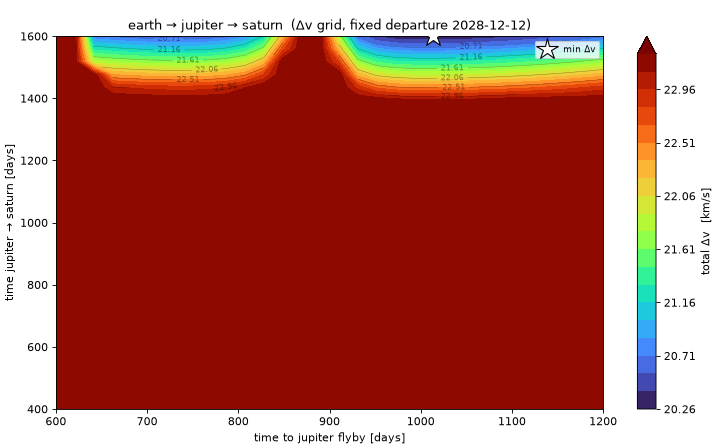

In [ ]:
flyby_grid = flyby_porkchop(
    "earth", "jupiter", "saturn", best_jup["dep_date"],
    tof1_range=(600, 1200), tof2_range=(400, 1600),
    n_tof1=30, n_tof2=30, h_min_km=500.0,
)
flyby_best = flyby_grid["best"]
print(f"Best E→J→S trajectory (fixed dep {flyby_best['dep_date'].iso[:10]}):")
print(f"  tof₁={flyby_best['tof1_days']:.0f} d  tof₂={flyby_best['tof2_days']:.0f} d")
print(f"  Δv_dep={flyby_best['dv_depart_kms']:.2f}  Δv_flyby={flyby_best['dv_flyby_kms']:.3f}  "
      f"Δv_arr={flyby_best['dv_arrive_kms']:.2f}  total={flyby_best['dv_total_kms']:.2f} km/s")
plot_flyby_porkchop(flyby_grid)
plt.show()


### Step 4d — Two-Leg Trajectory (Interactive)

Both legs are Lambert arcs. They start from real ephemeris positions, at the best
(tof₁, tof₂) grid point found above. Use the slider to follow the spacecraft through
the Jupiter flyby and on to Saturn.


In [ ]:
plot_two_leg(flyby_best)


/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/Software/kalman/kalman-framework/.venv/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


## Step 5 — Propellant Budget, Burn Physics, and EKF Uncertainty

`TrajectoryControlManeuver` tracks propellant use with the Tsiolkovsky rocket
equation:

$$m_{\rm after} = m_{\rm before} \cdot e^{-\Delta v / (I_{\rm sp}\,g_0)}$$

$$t_{\rm burn} = \frac{\Delta m \cdot I_{\rm sp} \cdot g_0}{F_{\rm thrust}}$$

With Isp = 220 s and thrust = 22 N, a 10 m/s burn lasts only about 60 seconds and
consumes only about 6 kg. This is a small fraction of the 600 kg propellant reserve.
This is typical: TCMs use little propellant compared to the main orbit-insertion
burn. MRO's Mars orbit insertion (MOI), for example, used about 900 kg.

The right-hand plot shows the EKF's position uncertainty, σ_r, over the cruise. Each
TCM fires while this uncertainty still exists. So the filter's estimate of each burn
differs slightly from the true burn used to generate the truth trajectory. The drop
in uncertainty after each TCM is small, because the burns themselves are small. DSN
tracking noise, not burn size, mainly drives the filter's uncertainty.


In [ ]:
SECONDS_PER_DAY = 86400.0

print("Propellant budget for this mission")
print("─" * 52)
print("  Spacecraft dry mass : %6.0f kg" % tcm.dry_mass)
print("  Launch wet mass     : %6.0f kg" % tcm._wet_mass_init)
print("  Total propellant    : %6.0f kg" % (tcm._wet_mass_init - tcm.dry_mass))
print()
for burn in tcm.burns:
    dv_leverage_km = burn["dv_ms"] * 1e-3 * burn["tof_rem_days"] * SECONDS_PER_DAY / 1e6   # Mm
    print("  TCM-%-2d  t=%5.1f d  Δv=%6.2f m/s  burn=%5.1f s  "
          "Δm=%5.2f kg  arrival leverage ≈ %.0f km"
          % (burn["tcm_idx"], burn["t_days"], burn["dv_ms"], burn["burn_s"],
             burn["prop_kg"], dv_leverage_km * 1e3))
print()
print("  Total TCM Δv        : %6.2f m/s" % sum(burn["dv_ms"] for burn in tcm.burns))
print("  Total Δm consumed   : %6.2f kg  (%.2f %% of propellant)"
      % (tcm.propellant_consumed_kg,
         100.0 * tcm.propellant_consumed_kg / max(tcm._wet_mass_init - tcm.dry_mass, 1)))
print("  Propellant remaining: %6.2f kg  (reserved for Mars Orbit Insertion)"
      % tcm.propellant_remaining_kg)
print()
print("Reference:  MRO TCM-1 = 18.5 m/s (~12 kg),  MSL TCM-1 = 5.0 m/s (~3 kg)")

Propellant budget for this mission
────────────────────────────────────────────────────
  Spacecraft dry mass :    600 kg
  Launch wet mass     :   1200 kg
  Total propellant    :    600 kg

  TCM-1   t=  5.0 d  Δv= 30.69 m/s  burn=1662.2 s  Δm=16.95 kg  arrival leverage ≈ 813 km
  TCM-2   t= 30.0 d  Δv= 32.21 m/s  burn=1719.4 s  Δm=17.53 kg  arrival leverage ≈ 783 km
  TCM-3   t= 90.0 d  Δv= 44.85 m/s  burn=2351.4 s  Δm=23.98 kg  arrival leverage ≈ 858 km

  Total TCM Δv        : 107.75 m/s
  Total Δm consumed   :  58.46 kg  (9.74 % of propellant)
  Propellant remaining: 541.54 kg  (reserved for Mars Orbit Insertion)

Reference:  MRO TCM-1 = 18.5 m/s (~12 kg),  MSL TCM-1 = 5.0 m/s (~3 kg)


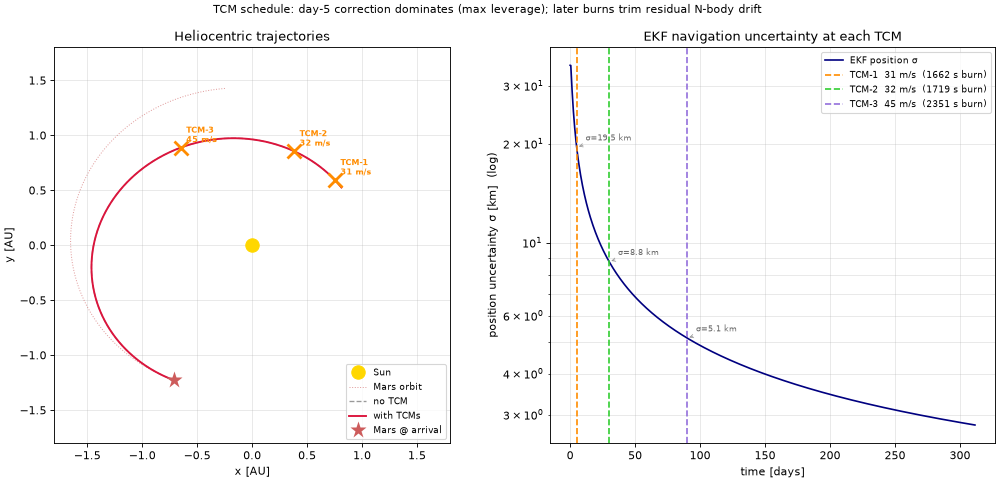

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))

# ── Left: heliocentric overview with all TCM events ──────────────────────
ax = axes[0]
mars_trk2 = mc.planet_track("mars", len(hist_cor)) / AU
ax.plot([0], [0], "o", color="gold", ms=12, zorder=6, label="Sun")
ax.plot(mars_trk2[:, 0], mars_trk2[:, 1], ":", color="indianred", lw=0.9, alpha=0.6, label="Mars orbit")
ax.plot(hist_nom[:, 0] / AU, hist_nom[:, 1] / AU, "--", color="0.6", lw=1.2, label="no TCM")
ax.plot(hist_cor[:, 0] / AU, hist_cor[:, 1] / AU, color="crimson", lw=1.7, label="with TCMs")
for burn in tcm.burns:
    burn_idx = int(round(burn["t_ks"] / dt))
    burn_pos = hist_cor[burn_idx, :2] / AU
    ax.plot([burn_pos[0]], [burn_pos[1]], "x", color="darkorange", ms=13, mew=2.5, zorder=6)
    ax.annotate("TCM-%d\n%.0f m/s" % (burn["tcm_idx"], burn["dv_ms"]),
                burn_pos, xytext=(5, 5), textcoords="offset points",
                fontsize=7, color="darkorange", fontweight="bold")
mars_pos = mars_arr[:2] / AU
ax.plot([mars_pos[0]], [mars_pos[1]], "*", color="indianred", ms=16, mec="none", zorder=5,
        label="Mars @ arrival")
ax.autoscale(False)
ax.set_xlim(-1.8, 1.8)
ax.set_ylim(-1.8, 1.8)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.set_title("Heliocentric trajectories")
ax.legend(fontsize=7.8, loc="lower right")
ax.grid(alpha=0.3)

# ── Right: EKF position uncertainty + TCM timing ─────────────────────────
ax2 = axes[1]
Pk_all = np.asarray(est_mc.Pk)
sigma_r = np.sqrt(np.trace(Pk_all[:, :3, :3], axis1=1, axis2=2)) * 1e3
t_days_all = np.arange(len(sigma_r)) * dt / DAY
ax2.semilogy(t_days_all, sigma_r, color="navy", lw=1.5, label="EKF position σ")
colors_tcm = ["darkorange", "limegreen", "mediumpurple"]
for burn, col in zip(tcm.burns, colors_tcm):
    t_burn_d = burn["t_days"]
    burn_idx = int(round(burn["t_ks"] / dt))
    sigma_at_burn = float(sigma_r[min(burn_idx, len(sigma_r) - 1)])
    ax2.axvline(t_burn_d, color=col, ls="--", lw=1.5,
                label="TCM-%d  %.0f m/s  (%.0f s burn)"
                % (burn["tcm_idx"], burn["dv_ms"], burn["burn_s"]))
    ax2.annotate("σ=%.1f km" % sigma_at_burn,
                 xy=(t_burn_d, sigma_at_burn),
                 xytext=(8, 6), textcoords="offset points",
                 fontsize=7.5, color="0.4",
                 arrowprops=dict(arrowstyle="->", color="0.6", lw=0.7))
ax2.set_xlabel("time [days]")
ax2.set_ylabel("position uncertainty σ [km]  (log)")
ax2.set_title("EKF navigation uncertainty at each TCM")
ax2.legend(fontsize=8.0)
ax2.grid(alpha=0.3, which="both")

plt.suptitle("TCM schedule: day-5 correction dominates (max leverage); "
             "later burns trim residual N-body drift", fontsize=10)
plt.tight_layout()
plt.show()

# ── Interactive EKF replay with all burns ────────────────────────────────
burns_for_plot = [(int(round(burn["t_ks"] / dt)), burn["dv_vec_kms"]) for burn in tcm.burns]
mc.plot(est_mc, sample=trip_mc, interactive=True, frames=30,
        burns=burns_for_plot, no_burn=trip_nom)

## Step 6 — Cassini VVEJGA: Replicating the Grand Tour

Cassini-Huygens launched on 15 October 1997. It took 6 years and 9 months to reach
Saturn, using one of the most complex gravity-assist sequences ever flown:

> Earth → Venus → Venus → Earth → Jupiter → Saturn

This route is called VVEJGA: Venus-Venus-Earth-Jupiter Gravity Assist. The spacecraft
made three trips around the inner solar system before heading to the outer solar
system. The flybys added about 15 km/s of speed at no fuel cost:

| Leg | Departure | Arrival | TOF |
|-----|-----------|---------|-----|
| 1  | Earth     | Venus   | 1997-10-15 → 1998-04-26 | 193 d |
| 2  | Venus     | Venus   | 1998-04-26 → 1999-06-24 | 424 d |
| 3  | Venus     | Earth   | 1999-06-24 → 1999-08-18 |  55 d |
| 4  | Earth     | Jupiter | 1999-08-18 → 2000-12-30 | 500 d |
| 5  | Jupiter   | Saturn  | 2000-12-30 → 2004-07-01 | 1279 d |

`chain_lambert` solves five Lambert arcs, one per leg, using the real historical
flyby dates. `plot_multi_leg` then animates the full trajectory, from launch to
Saturn orbit insertion. The patched-conic solver gives an approximate Δv at each
flyby point. The true correction burns were under 1 m/s; the planets' gravity did the
real work.


In [ ]:
from astropy.time import Time
from kalman.apps.astro.space import chain_lambert, plot_multi_leg

cassini_sequence = ["earth", "venus", "venus", "earth", "jupiter", "saturn"]
cassini_dates = [
    Time("1997-10-15"),   # launch
    Time("1998-04-26"),   # Venus 1 flyby
    Time("1999-06-24"),   # Venus 2 flyby
    Time("1999-08-18"),   # Earth flyby
    Time("2000-12-30"),   # Jupiter flyby
    Time("2004-07-01"),   # Saturn orbit insertion
]

legs = chain_lambert(cassini_sequence, cassini_dates)

print("Cassini VVEJGA — Lambert solution per leg")
print(f"{'Leg':>3}  {'Route':>18}  {'TOF (d)':>8}  {'Δv_flyby (m/s)':>15}")
for i, leg in enumerate(legs):
    route = f"{leg['departure']}→{leg['arrival']}"
    print(f"{i+1:>3}  {route:>18}  {leg['tof_days']:>8.0f}  {leg['dv_flyby_kms']*1e3:>15.0f}")

total_tof = sum(leg["tof_days"] for leg in legs)
print(f"\nTotal mission time: {total_tof:.0f} days  ({total_tof/365.25:.1f} years)")

# Two-panel: LEFT = inner solar system (VVEJ flybys), RIGHT = full Earth→Saturn scale.
# zoom_lim="auto" sizes the left panel to the tightest box that fits all inner arcs
# (< 4 AU) without clipping; legs that exit the zoom box are suppressed there to avoid
# discontinuous line artefacts (e.g. the Earth→Jupiter leg clipping at x = 2.1 AU).
plot_multi_leg(legs,
               title="Cassini VVEJGA  (1997–2004)  —  Earth → Venus → Venus → Earth → Jupiter → Saturn",
               extra_planets=("mars",),
               frames=30,
               zoom_lim="auto")

Cassini VVEJGA — Lambert solution per leg
Leg               Route   TOF (d)   Δv_flyby (m/s)
  1         earth→venus       193                0
  2         venus→venus       424             4412
  3         venus→earth        55             3814
  4       earth→jupiter       500             5912
  5      jupiter→saturn      1279             1969

Total mission time: 2451 days  (6.7 years)


## Further Reading

- **More complex gravity assists.** Cassini used the VVEJGA route (Venus-Venus-Earth-
  Jupiter) to reach Saturn. Try chaining more `flyby_porkchop` calls, or extend
  `hohmann_sequence` to four legs.
- **Autonomous optical navigation.** Real probes update the EKF with star-tracker
  bearing measurements, which give angle only, not range. Try swapping the DSN
  position model for an `H = angle` observation matrix. Observe how the covariance
  grows differently.
- **Back to the pad.** Notebook 06, Rocket Science, covers liftoff, guided ascent,
  and the gimballed landing.
